# A Guide to Robust Regression

**Blog by Connor Yablonski, Zarko Cosovik, Anika Shridhar (University of San Francisco)

## Introduction

One of the fundational goals of statistics is the ability to predict the future. While this goal is an impossible frontier to reach, even a small change in predictive accuracy can be the difference between fortune and failure. Elections are won and lost, hedge fund managers fired or promoted, and gamblers make it big or ruin their lives over a difference of a few percentage points in predictive accuracy. To put this into concrete terms, a sports gambler betting on simple wins and losses needs to win 52.38% of their bets to break even. [1] Winning 54% could net them a great fortune in the long run, and yet hitting on 50% of bets would result in devastating losses. The question is: how do we reliably predict the future? As you may realize by the success of Las Vegas casinos and sportbooks, we humans are not naturals at factoring in every variable, weighing them, and coming to a valid conclusion on our own. That is the beauty of **linear regression**.

In short, linear regression is a model that estimates the relationship between a response variable, or the value we are trying to predict (think price of a stock or chance of a team winning), and one or more explanatory variables. Creating a linear regression model involves the collection of a large set of data, and the "fitting" of the explanatory columns of that dataset to the response column.

Linear regression is a powerful tool, but it has its disadvantages. Particularly, there are assumptions about the characteristics of the dataset that must be met in order for traditional linear regression to be valid. However, the collection of a large dataset can be an expensive and time-consuming endevour. That is where the topic of the article, **robust regression**, comes into play. Robust regression is a form of linear regression that seeks to limit the effect that violations of assumptions have on the model.


Before we dive into the details of robust regression, lets first introduce the basics of traditional linear regression.

## The Basics - Linear Regression

In simple terms, Linear Regression is a method to identify the best straight line that goes through a set of data points, in order to understand the relationships in the data and make predictions accordingly. To demonstrate with a simple example, let's say you have the data of the temperature outside and the sales of the ice-cream corresponding to the temperature that looks like this:

| Temperature (degF) | Ice-cream Sales ($) |
| ---------------- | ------------------- |
| 60               | 120                 |
| 70               | 150                 |
| 80               | 200                 |
| 90               | 260                 |

With linear regression, you can represent this data in the form of a straight line that best represents this pattern, which in this case would be: 

Sales = 2.5 x Temperature - 30

So, if you would want to predict what would be the sales tomorrow if the temperature is 100 degrees, the sales would be (2.5 x 100 - 30) ie 220$

We can interpret this as with a unit increase in temperature, the sales increases by 2.5 dollars. 
And when the temperature is 0 degrees, the sales would be -30 (which would not make sense in real life, but this is how we interpret statistically)

Here's a simple script to plot the above data:

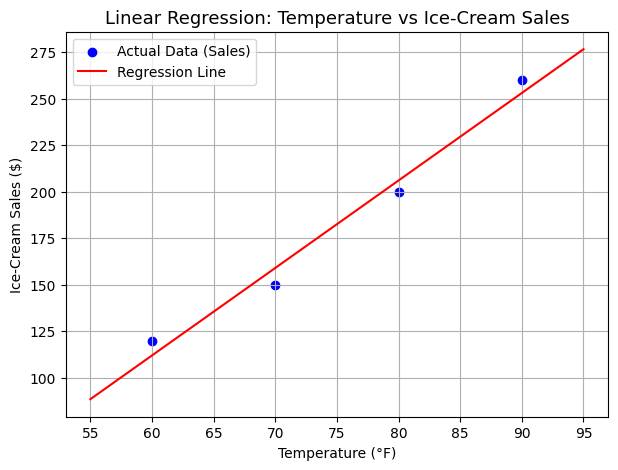

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Sample Data: Temperature vs Ice-Cream Sales
temperature = np.array([60, 70, 80, 90]).reshape(-1, 1)
sales = np.array([120, 150, 200, 260])

# Create and Fit the Model
model = LinearRegression()
model.fit(temperature, sales)

# Generate Predicted Values
temp_range = np.linspace(55, 95, 100).reshape(-1, 1)   # smooth range for plotting
pred_sales = model.predict(temp_range)

# Plot the Data and Regression Line
plt.figure(figsize=(7, 5))
plt.scatter(temperature, sales, color='blue', label='Actual Data (Sales)')
plt.plot(temp_range, pred_sales, color='red', label='Regression Line')

# Add Titles and Labels
plt.title("Linear Regression: Temperature vs Ice-Cream Sales", fontsize=13)
plt.xlabel("Temperature (°F)")
plt.ylabel("Ice-Cream Sales ($)")
plt.legend()
plt.grid(True)
plt.show()


To understand the technicality of linear regression, we would need to know the below terms:

- Residual:  This is the difference between what the regression line has predicted and what is the actual value.

In the ice-cream example, say if the actual sales tomorrow was 300$ when the temperature was 100 degrees, then the residual calculated would be 300-220 ie 80$. The residuals can either be positive or negative, if positive, the actual value would be above the regression line, if negative the actual value would be below the regression line.

- Outlier:  An observation with a large residual, which means that the data point is very different as compared to the rest of the data and would not fit in the regression line.

In the ice-cream example, say if we had another observation as shown below:

| Temperature (degF) | Ice-cream Sales ($) |
| ---------------- | ------------------- |
| 60               | 120                 |
| 70               | 150                 |
| 80               | 200                 |
| 90               | 260                 |
| 85               | 600                 |


The sales of 600$ for a temperature at 85 degrees, doesn't follow the pattern like the other data points and hence this observation is considered an "outlier".

- Ordinary Least Squares (OLS): This is a method for finding that line that best represents the data. It is calculated by summing up the residuals squared, and the line is chosen that minimizes this sum. This is a very standard method of linear regression, but it has its pitfalls.

## Digging Deeper

In more technical terms, linear regression is a statistical method of modeling the relationship between the predictor and the response. It fits a straight line to the data, and the coefficients are based on the OLS calculation.

Traditional linear regression is sensitive to outliers because the errors are squared, so the big errors affect the model more than the small errors. This is why OLS is sensitive to outliers as only a few can distort the model and make it unsuitable for making predictions.

When we look at the distribution of house prices, we find that it is skewed. Although most houses are in a close price range, there are outliers, very expensive houses which can negatively affect the result of OLS, by causing the model to have suboptimum estimates. Since data with outliers makes OLS results less precise, we turn to ROBUST REGRESSION to address this issue.

One of the most common robust regression methods is HUBER REGRESSION. This method behaves like OLS when the errors are small, but is less affected by large errors.

### What is Huber Regression?

Hubber Regression is fitting majority of data accurately, while acknowledging that outliers exits, and using a loss function that grows more slowly in presence of large residuals. This means that extreme values have less influence on the fitted model, reducing the impact of outliers.

Below we compare OLS to Huber Regression to show how Huber Regression finds a more realistic fit when outliers are present.

The 3D plot shows that the Huber Regression plane provides a more accurate description of the distribution than does the OLS. Using an interactive app’s slider to add more outliers, we see how the estimates change when with added outliers.

What we find is that OLS and Huber Regression make the same fit when there are no outliers, but as we add more outliers, we can see the two lines diverge.

In fact, by the first outlier added it is already clear which one is the favorite, as the OLS line is pulled up at the left end, while Huber Regression line is unaffected.

The more outliers we add the better the Huber Regression is performing compared to OLS.

### Comparison of OLS Vs Huber Regression

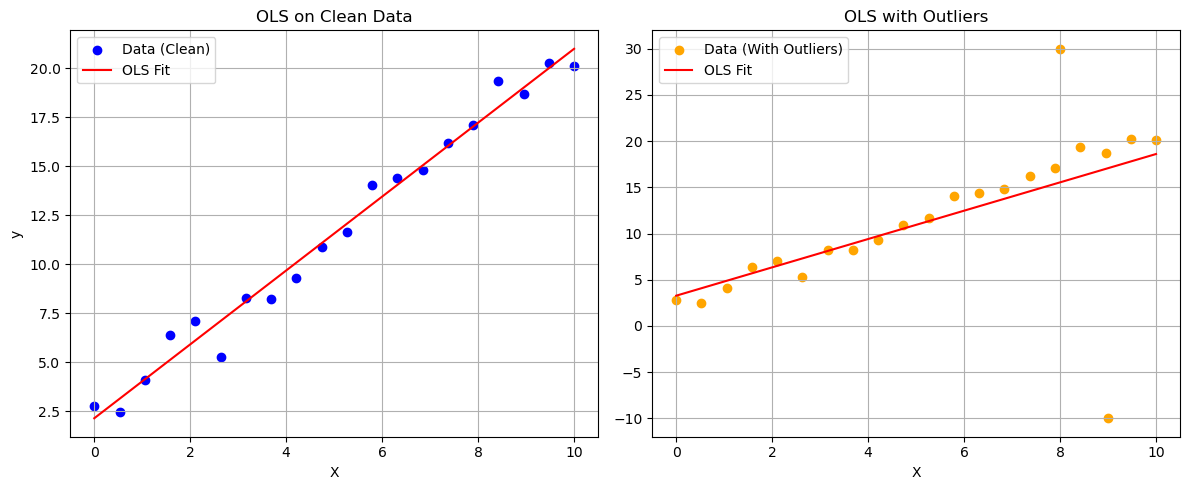

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Step 1: Create clean linear data
np.random.seed(0)
X = np.linspace(0, 10, 20)
y = 2 * X + 1 + np.random.normal(0, 1, size=X.shape)

# Reshape for sklearn
X_reshaped = X.reshape(-1, 1)

# Step 2: Fit OLS to clean data
model_clean = LinearRegression().fit(X_reshaped, y)
y_pred_clean = model_clean.predict(X_reshaped)

# Step 3: Add outliers
X_out = np.append(X, [8, 9])
y_out = np.append(y, [30, -10])
X_out_reshaped = X_out.reshape(-1, 1)

# Step 4: Fit OLS to data with outliers
model_outliers = LinearRegression().fit(X_out_reshaped, y_out)
y_pred_outliers = model_outliers.predict(X_reshaped)

# Step 5: Plot
plt.figure(figsize=(12, 5))

# Left: Clean data
plt.subplot(1, 2, 1)
plt.scatter(X, y, label='Data (Clean)', color='blue')
plt.plot(X, y_pred_clean, color='red', label='OLS Fit')
plt.title("OLS on Clean Data")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.grid(True)

# Right: With outliers
plt.subplot(1, 2, 2)
plt.scatter(X_out, y_out, label='Data (With Outliers)', color='orange')
plt.plot(X, y_pred_outliers, color='red', label='OLS Fit')
plt.title("OLS with Outliers")
plt.xlabel("X")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

The plots above show that the line fits the data better when there are no outliers.

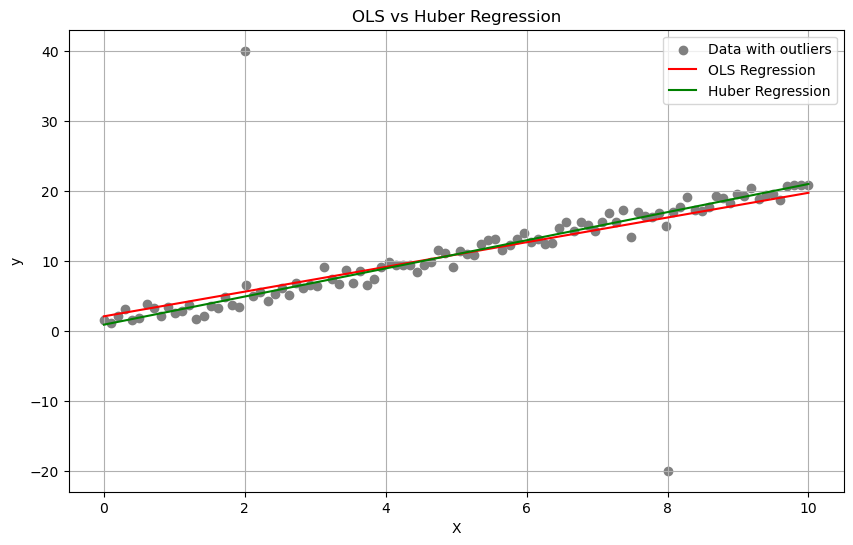

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, HuberRegressor
from sklearn.metrics import mean_squared_error

# Generate synthetic data
np.random.seed(42)
X = np.linspace(0, 10, 100)
y = 2 * X + 1 + np.random.normal(0, 1, size=X.shape)

# Add outliers
X_out = np.append(X, [2, 8])
y_out = np.append(y, [40, -20])

X_out = X_out.reshape(-1, 1)

# Fit models
ols = LinearRegression().fit(X_out, y_out)
huber = HuberRegressor().fit(X_out, y_out)

# Predictions
x_plot = np.linspace(0, 10, 100).reshape(-1, 1)
y_ols = ols.predict(x_plot)
y_huber = huber.predict(x_plot)

# Plot
plt.figure(figsize=(10, 6))
plt.scatter(X_out, y_out, color='gray', label='Data with outliers')
plt.plot(x_plot, y_ols, color='red', label='OLS Regression')
plt.plot(x_plot, y_huber, color='green', label='Huber Regression')
plt.legend()
plt.title("OLS vs Huber Regression")
plt.xlabel("X")
plt.ylabel("y")
plt.grid(True)
plt.show()

The plot above shows the comparisson of OLS Regression and the Huber loss model which is designed to combat outliers and seems to fit the data better than OLS Regression.

### Let's understand the difference between Least Squares Method and Absolute Deviation Method

In the Least Squares Method, we are trying to MINIMIZE the AVERAGE SQUARED DIFFERENCES between the actual and the predicted values.

The Mean Squared Error loss function is defined as:

$$
MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$




In the Least Absolute Deviation Method, we are trying to MINIMIZE the AVERGAE ABSOLUTE DIFFERENCES between the actual and predicted values.

The Mean Absolute Error loss function is defined as:

$$
MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|
$$


## Huber Regressor Algorithm

This algorithm combines the advantages of Least Squares Method AND the Absolute Deviation Method in order to MINIMIZE the impact of outliers in the data !

### About the Huber Loss Function

The Huber Loss Function (represented by L(y,yhat) as shown below) smoothly transitions from (Mean Squared Error) MSE to (Mean Absolute Error) MAE based on a threshold parameter called epsilon δ, which controls the point where the loss function transitions from quadratic to linear.

It can be defined as :


$$
L_\delta(y, \hat{y}) =
\begin{cases}
\frac{1}{2}(y - \hat{y})^2, & \text{for } |y - \hat{y}| \le \delta \\
\delta \, (|y - \hat{y}| - \frac{1}{2}\delta), & \text{for } |y - \hat{y}| > \delta
\end{cases}
$$


We can write the residual as 
$$
r_i = y_i - \hat{y}_i
$$


The above Loss function formula can be read in simple terms as below:


For residuals less than or equal to epsilon: L(residual) = 0.5 * residual^2

For residuals greater than epsilon: L(residual) = epsilon * (abs(residual) - 0.5 * epsilon)

At the point

$$
|r_i| = \delta
$$

the function switches from a quadratic shape to a linear shape.


### Loss Function Behaviour

1. Quadratic (MSE-like) for small residuals: When ∣residual∣≤δ, the loss is *quadratic*. This makes the model sensitive to small errors, similar to the mean squared error (MSE), ensuring that it fits the data points closely when errors are small. 

2. Linear (MAE-like) for large residuals: When ∣residual∣>δ , the loss becomes *linear*. This limits the influence of outliers by reducing the penalty for large residuals, similar to the mean absolute error (MAE), making the model more robust to extreme values.

This behavior allows the Huber Regressor to be robust to outliers while still being sensitive to small deviations in the data.

### Comparison with OLS and MAE

OLS (Ordinary Least Squares): Uses a fully quadratic loss, making it very sensitive to outliers, as large errors are penalized more heavily.

MAE (Mean Absolute Error): Uses a fully linear loss, making it robust to outliers, but it may underperform in capturing small deviations in the data.

Huber Regressor: Combines the two, being *quadratic* for SMALL residuals (like OLS) and *linear* for LARGE residuals (like MAE)

### Goal

The Huber Regressor minimizes the sum of the Huber losses for all data points:

$$
\min_{\hat{y}} \sum_{i=1}^{n} L_\delta(r_i)
$$
 


This is done using iterative methods because the Huber loss function is non-smooth at point where the magnitude of the residual becomes equal to the threshold parameter


When we iteratively update the coefficients using the Huber loss function, the HuberRegressor algorithm finds a set of coefficients that MINIMIZES the OVERALL LOSS while being less influenced by outliers compared to OLS regression.

This is how HuberRegressor algorithm strikes a balance between the robustness of the absolute deviation loss and the efficiency of the squared loss!

### How to choose the parameter δ ?


Small δ: The model will be more robust to outliers, but less sensitive to normal data points.


Large δ: The model behaves more like OLS, being more sensitive to small errors but also more influenced by outliers.

The ideal value of δ is usually determined using cross-validation.

### Advantages of Huber Regression

1. Robustness to Outliers: The robustness is acheived by using a hybrid loss function that smoothly transitions between the squared loss (MSE) and the absolute loss (MAE). This makes the algorithm downweight the influence of outliers on the parameter estimates.

2. Balance between Least Squares and Absolute Deviation: It leverages the efficiency of OLS regression when the residuals are normally distributed, whilst providing robustness to outliers by incorporating the absolute deviation loss. This combination allows the algorithm to provide reliable parameter estimates in the presence of both small and large deviations from the model assumptions.

3. Continuity and Differentiability: The Huber loss function is continuous and differentiable, ensuring that optimization algorithms can be applied effectively to minimize the loss function. 

4. Tunable Robustness: The HuberRegressor allows you to control the robustness to outliers through the epsilon parameter. By adjusting the epsilon value, you can customize the level of robustness to match the characteristics of your dataset. Smaller epsilon values emphasize the squared loss (MSE), making the model more similar to OLS regression, while larger epsilon values emphasize the absolute loss (MAE), enhancing robustness to outliers.

5. Computational Efficiency: Although the HuberRegressor may be slightly computationally more expensive than OLS regression due to the hybrid loss function, it is generally more efficient compared to some other robust regression techniques like RANSAC (Random Sample Consensus) or Theil-Sen estimator. This is useful when working with large datasets.

### Challenges of Huber Regression

1. Model Complexity: Robust regression techniques require complex computations compared to traditional methods,
 thereby increasing processing time and resource consumption.

2. Choice of Tuning Parameters: The performance depends on the selection of hyperparameters. The Huber regressor has a tuning parameter called epsilon (ε) that determines the threshold for the switch between a linear loss (MSE) and an absolute loss (MAE). Choosing an appropriate value for epsilon can be challenging and requires careful consideration as a smaller epsilon value emphasizes the use of the MSE loss, making the Huber regressor behave more like OLS regression, whereas a larger epsilon value emphasizes the use of the MAE loss, making it more robust to outliers.

3. Sensitivity to Outliers: Although the Huber regressor is designed to be more robust, it can still be sensitive to extreme outliers. If the dataset contains severe outliers,then the model performance can be impacted. 

5. Computational Complexity: The Huber regression algorithm is computationally more expensive compared to OLS regression due to the presence of the epsilon parameter and the use of a different loss function. 

6. Subjectivity in Loss Function Choice: The Huber regressor uses a hybrid loss function that transitions between MSE and MAE. The choice of the loss function can be somewhat subjective and depends on the specific requirements of the problem at hand. Different loss functions can yield different results, so it’s important to consider the trade-offs and understand the implications of the chosen loss function.

## Simulations

The first simulation here demonstrates how Huber Regression and the OLS model diverge as we add outliers. When the outliers are evenly dispersed above and below the dataset (like in number 3) the differences are minimal. But even by adding just one outlier (like in number 1) we see that the Huber regression line follows the trend of the data better than the OLS model.

<iframe src="https://linear-regression-final-project-h4p4.onrender.com" width="100%" height="800" style="border:none;"></iframe>

This next simulation demonstrates the difference between Huber regression and OLS in a 3-dimensional space. Other than being a fun graphic to play around with, this serves as a reminder that linear regression is not limited to 2D (just one predictive variable). While we can't show what a 4D linear regression model looks like, we can still use both the OLS and Huber regression to model trends with any number of predictive variables. And in these higher dimensional cases, Huber regression still holds as the method less susceptible to outliers.

<iframe src="_static/ols_vs_huber_js.html" width="100%" height="800" style="border:none;"></iframe>

## References

1. Break even point in sports betting: https://medium.com/@BetLocksmith/the-single-most-important-number-in-sports-betting-092f97777e5e

2. Peter J. Huber (1964). Robust Estimation of a Location Parameter

3. Robust regression: https://en.wikipedia.org/wiki/Robust_regression

4. Comprehensive guide to Huber Regression : https://nachi-keta.medium.com/a-comprehensive-guide-to-huber-regression-balancing-efficiency-and-robustness-for-reliable-d65f122f317f

5. Tiny ML- https://medium.com/@thommaskevin/tinyml-huber-regression-315f30129ab3